In [1]:
import sys
from pathlib import Path

from sklearn.feature_extraction.text import (
    CountVectorizer,
    TfidfVectorizer,
)

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.config import (
    DATASET_NAME,
    MAX_TOKENS,
    RAW_DATA_DIR,
    SEQUENCE_LENGTH,
)
from src.data import (
    load_data,
    remove_duplicates,
    split_data,
    validate_data,
)
from src.evaluation import (
    evaluate_classical_model,
    evaluate_nlp_model,
    plot_loss,
)
from src.models.classical import (
    train_linear_svc,
    train_logistic_regression,
    train_naive_bayes,
)
from src.models.rnn import (
    build_gru,
    build_lstm,
    build_simple_rnn,
    compile_model,
    fit_model,
)
from src.models.transformer import build_transformer_classifier
from src.preprocessing import (
    create_vectorizer,
    fit_vectorizer,
    validate_non_empty_sequences,
    validate_right_padding,
    vectorize_text,
)


I0000 00:00:1791537979.213827   44049 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791537979.243632   44049 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791537979.955245   44049 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
dataset_path = RAW_DATA_DIR / DATASET_NAME

df = load_data(dataset_path)

validate_data(df)

print(f"Original dataset size: {len(df)}")

df = remove_duplicates(df)

print(f"Dataset size after duplicate removal: {len(df)}")


splits = split_data(df)

print("Dataset splits:")
print(f"Train:      {len(splits.X_train)}")
print(f"Validation: {len(splits.X_val)}")
print(f"Test:       {len(splits.X_test)}")

Original dataset size: 5572
Dataset size after duplicate removal: 5169
Dataset splits:
Train:      3617
Validation: 776
Test:       776


In [3]:
vectorizer = create_vectorizer(
    max_tokens=MAX_TOKENS,
    sequence_length=SEQUENCE_LENGTH,
)

fit_vectorizer(
    vectorizer,
    splits.X_train,
)

X_train_seq = vectorize_text(
    vectorizer,
    splits.X_train,
)

X_val_seq = vectorize_text(
    vectorizer,
    splits.X_val,
)

X_test_seq = vectorize_text(
    vectorizer,
    splits.X_test,
)

I0000 00:00:1791537980.325720   44049 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 2144 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


In [4]:
validate_non_empty_sequences(X_train_seq)
validate_non_empty_sequences(X_val_seq)
validate_non_empty_sequences(X_test_seq)

validate_right_padding(X_train_seq)
validate_right_padding(X_val_seq)
validate_right_padding(X_test_seq)

print("Sequence validation passed.")

Sequence validation passed.


In [5]:
tfidf_vectorizer = TfidfVectorizer()

X_train_tfidf = tfidf_vectorizer.fit_transform(splits.X_train)
X_test_tfidf = tfidf_vectorizer.transform(splits.X_test)

print(f"TF-IDF train shape: {X_train_tfidf.shape}")
print(f"TF-IDF test shape: {X_test_tfidf.shape}")

TF-IDF train shape: (3617, 7149)
TF-IDF test shape: (776, 7149)


In [6]:
logistic_model = train_logistic_regression(
    X_train_tfidf,
    splits.y_train,
)

svc_model = train_linear_svc(
    X_train_tfidf,
    splits.y_train,
)

naive_bayes_model = train_naive_bayes(
    X_train_tfidf,
    splits.y_train,
)

In [7]:
results = []

==================== Logistic Regression - TF-IDF ====================
Classification report:
              precision    recall  f1-score   support

         ham       0.97      1.00      0.98       678
        spam       0.96      0.77      0.85        98

    accuracy                           0.97       776
   macro avg       0.96      0.88      0.92       776
weighted avg       0.97      0.97      0.96       776

Confusion Matrix:
[[675   3]
 [ 23  75]]
Accuracy: 0.9665
Precision: 0.9615
F1 score: 0.8523
Recall score: 0.7653


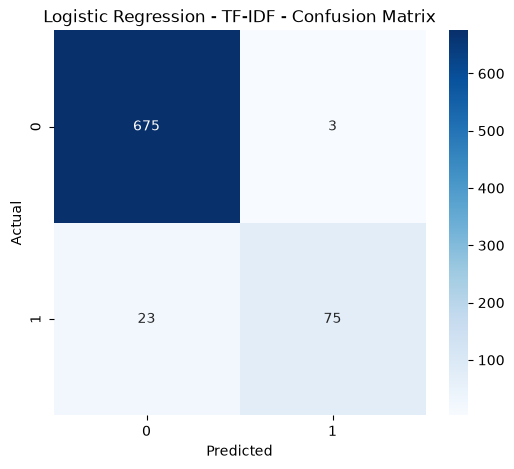

In [8]:
results.append(evaluate_classical_model(
    logistic_model,
    X_test_tfidf,
    splits.y_test,
    model_name="Logistic Regression - TF-IDF",
))

==================== Linear SVC - TF-IDF ====================
Classification report:
              precision    recall  f1-score   support

         ham       0.98      0.99      0.99       678
        spam       0.96      0.87      0.91        98

    accuracy                           0.98       776
   macro avg       0.97      0.93      0.95       776
weighted avg       0.98      0.98      0.98       776

Confusion Matrix:
[[674   4]
 [ 13  85]]
Accuracy: 0.9781
Precision: 0.9551
F1 score: 0.9091
Recall score: 0.8673


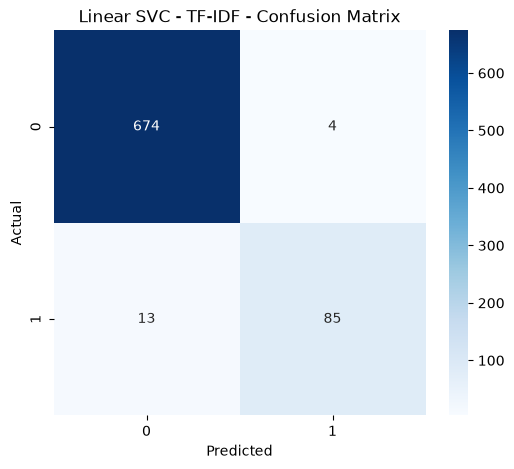

In [9]:
results.append(evaluate_classical_model(
    svc_model,
    X_test_tfidf,
    splits.y_test,
    model_name="Linear SVC - TF-IDF",
))

==================== Naive Bayes - TF-IDF ====================
Classification report:
              precision    recall  f1-score   support

         ham       0.96      1.00      0.98       678
        spam       1.00      0.70      0.83        98

    accuracy                           0.96       776
   macro avg       0.98      0.85      0.90       776
weighted avg       0.96      0.96      0.96       776

Confusion Matrix:
[[678   0]
 [ 29  69]]
Accuracy: 0.9626
Precision: 1.0000
F1 score: 0.8263
Recall score: 0.7041


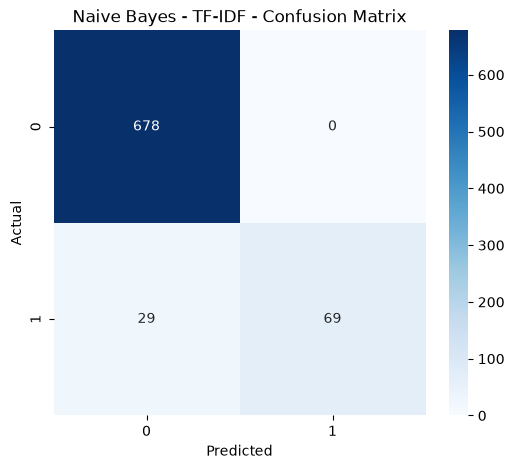

In [10]:
results.append(evaluate_classical_model(
    naive_bayes_model,
    X_test_tfidf,
    splits.y_test,
    model_name="Naive Bayes - TF-IDF",
))

In [11]:
bow_vectorizer = CountVectorizer()

X_train_bow = bow_vectorizer.fit_transform(splits.X_train)
X_test_bow = bow_vectorizer.transform(splits.X_test)

print(f"BoW train shape: {X_train_bow.shape}")
print(f"BoW test shape: {X_test_bow.shape}")

BoW train shape: (3617, 7149)
BoW test shape: (776, 7149)


In [12]:
svc_bow_model = train_linear_svc(
    X_train_bow,
    splits.y_train,
)

==================== Linear SVC - BoW ====================
Classification report:
              precision    recall  f1-score   support

         ham       0.98      1.00      0.99       678
        spam       0.97      0.85      0.90        98

    accuracy                           0.98       776
   macro avg       0.97      0.92      0.94       776
weighted avg       0.98      0.98      0.98       776

Confusion Matrix:
[[675   3]
 [ 15  83]]
Accuracy: 0.9768
Precision: 0.9651
F1 score: 0.9022
Recall score: 0.8469


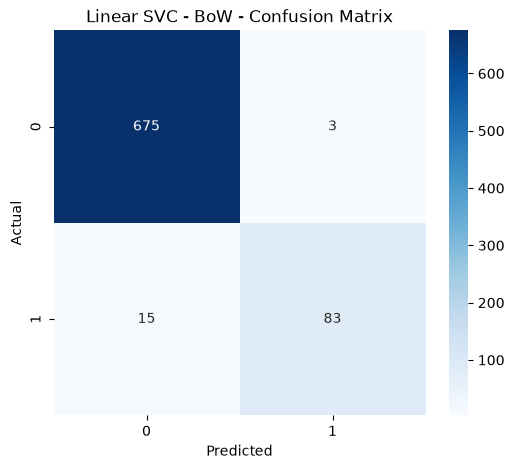

In [13]:
results.append(evaluate_classical_model(
    svc_bow_model,
    X_test_bow,
    splits.y_test,
    model_name="Linear SVC - BoW",
))

In [14]:
simple_rnn = build_simple_rnn(
    vocabulary_size=len(vectorizer.get_vocabulary()),
    sequence_length=SEQUENCE_LENGTH,
)

simple_rnn = compile_model(simple_rnn)

simple_rnn.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 50)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 50, 128)   │  1,280,000 │ input_layer[0][0] │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout1d   │ (None, 50, 128)   │          0 │ embedding[0][0]   │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 50)        │          0 │ input_layer[0][0] │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ simple_rnn          │ (None, 128)       │     32,896 │ spatial_dropout1… │
│ (SimpleRNN)         │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 1)         │        129 │ simple_rnn[0][0]  │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,313,025 (5.01 MB)

 Trainable params: 1,313,025 (5.01 MB)

 Non-trainable params: 0 (0.00 B)

In [15]:
y_train_numeric = (splits.y_train == "spam").astype("float32")
y_val_numeric = (splits.y_val == "spam").astype("float32")
y_test_numeric = (splits.y_test == "spam").astype("float32")

In [16]:
simple_rnn_history = fit_model(
    simple_rnn,
    X_train_seq,
    y_train_numeric,
    X_val_seq,
    y_val_numeric,
    batch_size=32,
)

Epoch 1/100


I0000 00:00:1791537989.719862   44148 service.cc:153] XLA service 0x5a273f675860 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1791537989.719875   44148 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 3050 Laptop GPU, Compute Capability 8.6 (Driver: 13.2.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.26.0)
I0000 00:00:1791537989.740320   44148 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1791537989.867845   44148 cuda_dnn.cc:461] Loaded cuDNN version 92600
I0000 00:00:1791537989.903161   44148 dot_merger.cc:481] Merging Dots in computation: functional_1_simple_rnn_1_while_body_247711_grad_247954_const_0__.17.clone.clone.clone.clone.clone.clone.clone.clone
I0000 00:00:1791537990.142323   44148 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good represen

 25/114 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8425 - loss: 0.4944

I0000 00:00:1791537991.419058   44148 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


114/114 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - accuracy: 0.8673 - loss: 0.3684 - val_accuracy: 0.9201 - val_loss: 0.2070 - learning_rate: 0.0010
Epoch 2/100
114/114 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9630 - loss: 0.1009 - val_accuracy: 0.9549 - val_loss: 0.1196 - learning_rate: 0.0010
Epoch 3/100
114/114 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9900 - loss: 0.0337 - val_accuracy: 0.9523 - val_loss: 0.1149 - learning_rate: 0.0010
Epoch 4/100
114/114 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9972 - loss: 0.0138 - val_accuracy: 0.9665 - val_loss: 0.0938 - learning_rate: 0.0010
Epoch 5/100
114/114 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9983 - loss: 0.0072 - val_accuracy: 0.9729 - val_loss: 0.0918 - learning_rate: 0.0010
Epoch 6/100
114/114 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9992 - loss: 0.0040 - val_accuracy: 0.9755 - val_loss: 0.0893 - learning_rate: 0.0010
Epoch 7/100
114/114 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9997 - loss: 0.0020 - val_

25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
==================== SimpleRNN ====================
Classification report:
              precision    recall  f1-score   support

         ham       0.99      1.00      0.99       678
        spam       0.98      0.90      0.94        98

    accuracy                           0.98       776
   macro avg       0.98      0.95      0.96       776
weighted avg       0.98      0.98      0.98       776

Confusion Matrix:
[[676   2]
 [ 10  88]]
Accuracy: 0.9845
Precision: 0.9778
F1 score: 0.9362
Recall score: 0.8980


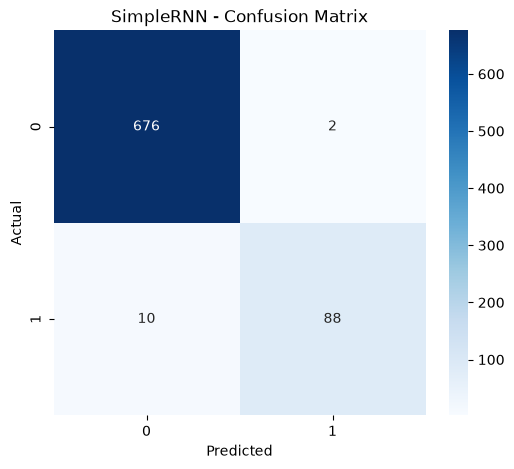

In [17]:
results.append(evaluate_nlp_model(
    simple_rnn,
    X_test_seq,
    splits.y_test,
    model_name="SimpleRNN",
))

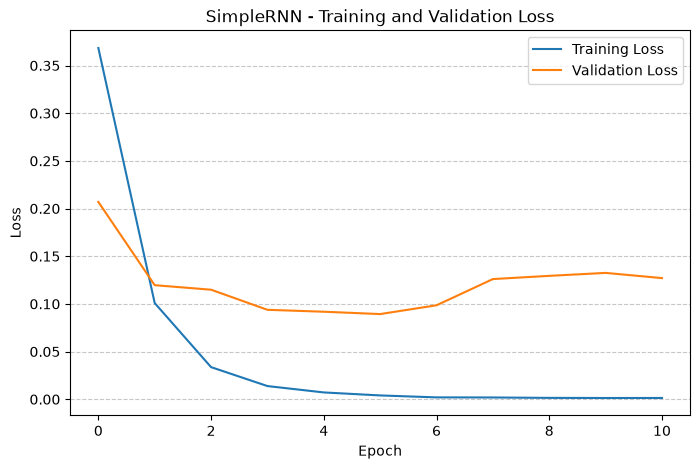

In [18]:
plot_loss(
    simple_rnn_history,
    model_name="SimpleRNN",
)

In [19]:
lstm_model = build_lstm(
    vocabulary_size=len(vectorizer.get_vocabulary()),
    sequence_length=SEQUENCE_LENGTH,
)

lstm_model = compile_model(lstm_model)

lstm_model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 50)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_1         │ (None, 50, 128)   │  1,280,000 │ input_layer_1[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout1d_1 │ (None, 50, 128)   │          0 │ embedding_1[0][0] │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_1         │ (None, 50)        │          0 │ input_layer_1[0]… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 128)       │    131,584 │ spatial_dropout1… │
│                     │                   │            │ not_equal_1[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 1)         │        129 │ lstm[0][0]        │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,411,713 (5.39 MB)

 Trainable params: 1,411,713 (5.39 MB)

 Non-trainable params: 0 (0.00 B)

In [20]:
lstm_history = fit_model(
    lstm_model,
    X_train_seq,
    y_train_numeric,
    X_val_seq,
    y_val_numeric,
    batch_size=32,
)

Epoch 1/100
114/114 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9193 - loss: 0.2605 - val_accuracy: 0.9781 - val_loss: 0.0935 - learning_rate: 0.0010
Epoch 2/100
114/114 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9884 - loss: 0.0495 - val_accuracy: 0.9626 - val_loss: 0.1121 - learning_rate: 0.0010
Epoch 3/100
114/114 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9931 - loss: 0.0215 - val_accuracy: 0.9781 - val_loss: 0.0848 - learning_rate: 0.0010
Epoch 4/100
114/114 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9978 - loss: 0.0087 - val_accuracy: 0.9742 - val_loss: 0.0820 - learning_rate: 0.0010
Epoch 5/100
114/114 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9889 - loss: 0.0355 - val_accuracy: 0.9781 - val_loss: 0.0723 - learning_rate: 0.0010
Epoch 6/100
114/114 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9989 - loss: 0.0050 - val_accuracy: 0.9768 - val_loss: 0.0893 - learning_rate: 0.0010
Epoch 7/100
109/114 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9994 - loss: 0.

25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
==================== LSTM ====================
Classification report:
              precision    recall  f1-score   support

         ham       0.98      1.00      0.99       678
        spam       0.97      0.89      0.93        98

    accuracy                           0.98       776
   macro avg       0.98      0.94      0.96       776
weighted avg       0.98      0.98      0.98       776

Confusion Matrix:
[[675   3]
 [ 11  87]]
Accuracy: 0.9820
Precision: 0.9667
F1 score: 0.9255
Recall score: 0.8878


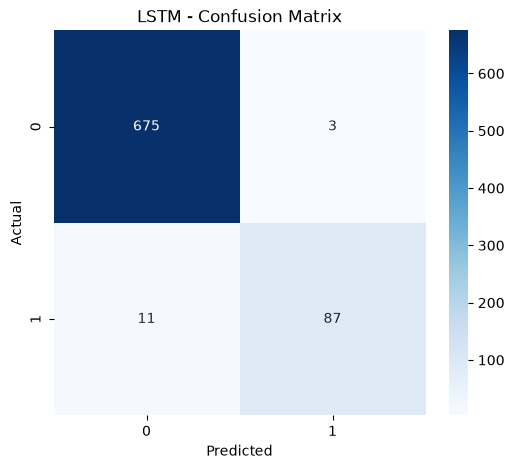

In [21]:
results.append(evaluate_nlp_model(
    lstm_model,
    X_test_seq,
    splits.y_test,
    model_name="LSTM",
))

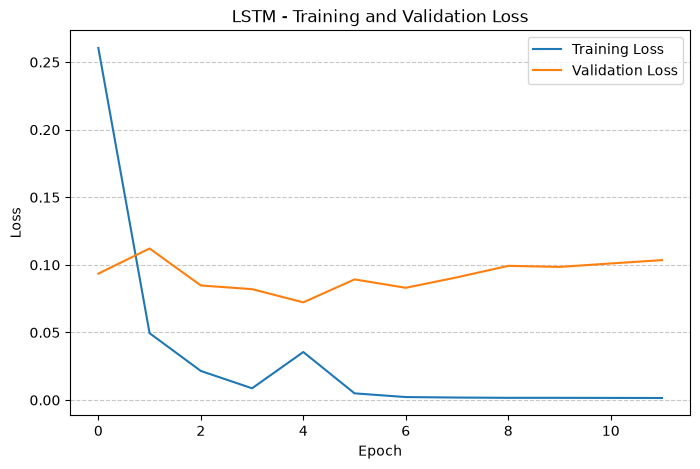

In [22]:
plot_loss(
    lstm_history,
    model_name="LSTM",
)

In [23]:
gru_model = build_gru(
    vocabulary_size=len(vectorizer.get_vocabulary()),
    sequence_length=SEQUENCE_LENGTH,
)

gru_model = compile_model(gru_model)

gru_model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 50)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_2         │ (None, 50, 128)   │  1,280,000 │ input_layer_2[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout1d_2 │ (None, 50, 128)   │          0 │ embedding_2[0][0] │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_2         │ (None, 50)        │          0 │ input_layer_2[0]… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gru (GRU)           │ (None, 128)       │     99,072 │ spatial_dropout1… │
│                     │                   │            │ not_equal_2[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 1)         │        129 │ gru[0][0]         │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,379,201 (5.26 MB)

 Trainable params: 1,379,201 (5.26 MB)

 Non-trainable params: 0 (0.00 B)

In [24]:
gru_history = fit_model(
    gru_model,
    X_train_seq,
    y_train_numeric,
    X_val_seq,
    y_val_numeric,
    batch_size=32,
)

Epoch 1/100
114/114 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9110 - loss: 0.2632 - val_accuracy: 0.9446 - val_loss: 0.1354 - learning_rate: 0.0010
Epoch 2/100
114/114 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9873 - loss: 0.0475 - val_accuracy: 0.9639 - val_loss: 0.1025 - learning_rate: 0.0010
Epoch 3/100
114/114 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9964 - loss: 0.0157 - val_accuracy: 0.9716 - val_loss: 0.0857 - learning_rate: 0.0010
Epoch 4/100
114/114 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9986 - loss: 0.0067 - val_accuracy: 0.9755 - val_loss: 0.0827 - learning_rate: 0.0010
Epoch 5/100
114/114 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9994 - loss: 0.0021 - val_accuracy: 0.9768 - val_loss: 0.0943 - learning_rate: 0.0010
Epoch 6/100
106/114 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9997 - loss: 0.0019
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
114/114 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9997 - loss: 0.00

25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
==================== GRU ====================
Classification report:
              precision    recall  f1-score   support

         ham       0.98      0.99      0.99       678
        spam       0.93      0.87      0.90        98

    accuracy                           0.98       776
   macro avg       0.96      0.93      0.94       776
weighted avg       0.98      0.98      0.98       776

Confusion Matrix:
[[672   6]
 [ 13  85]]
Accuracy: 0.9755
Precision: 0.9341
F1 score: 0.8995
Recall score: 0.8673


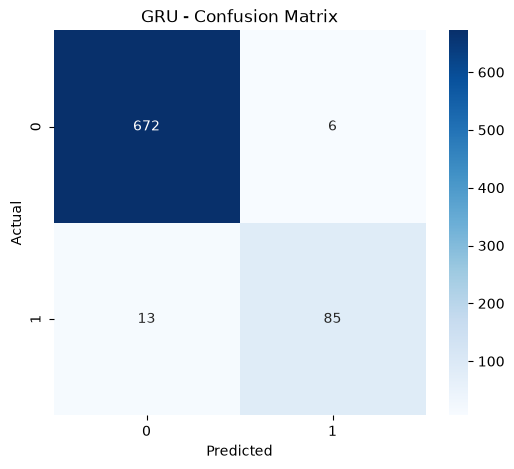

In [25]:
results.append(evaluate_nlp_model(
    gru_model,
    X_test_seq,
    splits.y_test,
    model_name="GRU",
))

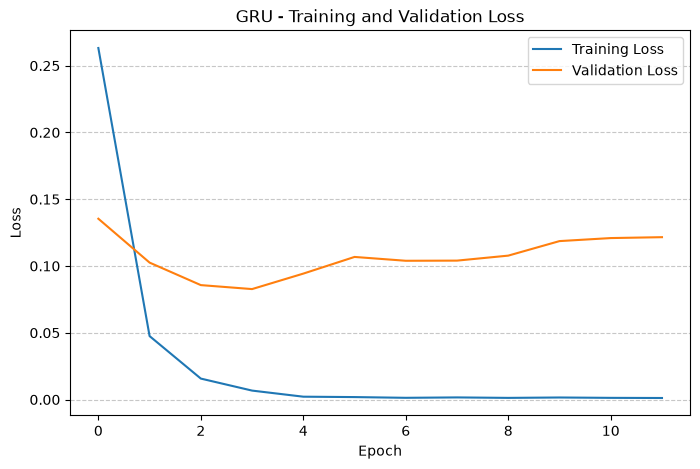

In [26]:
plot_loss(
    gru_history,
    model_name="GRU",
)

# ============================================================
# Transformer Encoder — Learning Implementation
# ============================================================

In [27]:
transformer_classifier = build_transformer_classifier(
    vocabulary_size=len(vectorizer.get_vocabulary()),
    sequence_length=SEQUENCE_LENGTH,
)

transformer_classifier.summary()

Model: "sms_transformer_classifier"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_tokens        │ (None, 50)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ token_embedding     │ (None, 50, 128)   │  1,280,000 │ input_tokens[0][… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 50, 128)   │          0 │ token_embedding[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ key_projection      │ (None, 50, 128)   │     16,384 │ add[0][0]         │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ query_projection    │ (None, 50, 128)   │     16,384 │ add[0][0]         │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_1 (Reshape) │ (None, 50, 8, 16) │          0 │ key_projection[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 50, 8, 16) │          0 │ query_projection… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transpose_1         │ (None, 8, 50, 16) │          0 │ reshape_1[0][0]   │
│ (Transpose)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_4         │ (None, 50)        │          0 │ input_tokens[0][… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transpose           │ (None, 8, 50, 16) │          0 │ reshape[0][0]     │
│ (Transpose)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transpose_3         │ (None, 8, 16, 50) │          0 │ transpose_1[0][0] │
│ (Transpose)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expand_dims         │ (None, 1, 50)     │          0 │ not_equal_4[0][0] │
│ (ExpandDims)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ matmul (Matmul)     │ (None, 8, 50, 50) │          0 │ transpose[0][0],  │
│                     │                   │            │ transpose_3[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expand_dims_1       │ (None, 1, 1, 50)  │          0 │ expand_dims[0][0] │
│ (ExpandDims)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ true_divide         │ (None, 8, 50, 50) │          0 │ matmul[0][0]      │
│ (TrueDivide)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ value_projection    │ (None, 50, 128)   │     16,384 │ add[0][0]         │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ where (Where)       │ (None, 8, 50, 50) │          0 │ expand_dims_1[0]… │
│                     │                   │            │ true_divide[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_2 (Reshape) │ (None, 50, 8, 16) │          0 │ value_projection

 Total params: 1,412,097 (5.39 MB)

 Trainable params: 1,412,097 (5.39 MB)

 Non-trainable params: 0 (0.00 B)

In [28]:
transformer_classifier = compile_model(
    transformer_classifier
)

In [29]:
transformer_history = fit_model(
    transformer_classifier,
    X_train_seq,
    y_train_numeric,
    X_val_seq,
    y_val_numeric,
    batch_size=32,
)

Epoch 1/100


I0000 00:00:1791538022.863341   44139 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_279672__.44
I0000 00:00:1791538023.029357   47495 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_54', 8 bytes spill stores, 8 bytes spill loads

I0000 00:00:1791538023.685047   47503 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_1_32', 48 bytes spill stores, 32 bytes spill loads

I0000 00:00:1791538024.656777   47500 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_1_36', 104 bytes spill stores, 56 bytes spill loads

I0000 00:00:1791538026.171442   47496 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_7', 120 bytes spill stores, 104 bytes spill loads

I0000 00:00:1791538026.827964   47506 subprocess_com

108/114 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8909 - loss: 0.2578

I0000 00:00:1791538032.785031   44140 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_279672__.50
I0000 00:00:1791538032.889521   44140 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
I0000 00:00:1791538033.294139   47744 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_10', 84 bytes spill stores, 68 bytes spill loads

I0000 00:00:1791538033.548428   44140 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
I0000 00:00:1791538033.862794   44140 dot_search_space.cc:240] All configs were filtered out because none o

114/114 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - accuracy: 0.8938 - loss: 0.2509

I0000 00:00:1791538039.169458   44140 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_280655__.23
I0000 00:00:1791538041.321879   44142 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_280655__.23


114/114 ━━━━━━━━━━━━━━━━━━━━ 22s 104ms/step - accuracy: 0.8938 - loss: 0.2509 - val_accuracy: 0.9214 - val_loss: 0.2164 - learning_rate: 0.0010
Epoch 2/100
114/114 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9762 - loss: 0.0757 - val_accuracy: 0.9742 - val_loss: 0.0998 - learning_rate: 0.0010
Epoch 3/100
114/114 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9862 - loss: 0.0360 - val_accuracy: 0.9549 - val_loss: 0.1364 - learning_rate: 0.0010
Epoch 4/100
114/114 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9771 - loss: 0.0724 - val_accuracy: 0.9742 - val_loss: 0.0850 - learning_rate: 0.0010
Epoch 5/100
114/114 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9997 - loss: 0.0027 - val_accuracy: 0.9665 - val_loss: 0.1650 - learning_rate: 0.0010
Epoch 6/100
109/114 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9994 - loss: 0.0030
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
114/114 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9994 - loss: 0.0029 - val_

I0000 00:00:1791538052.597110   44148 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_286975__.8


21/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step

I0000 00:00:1791538053.993086   44148 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_287326__.18


25/25 ━━━━━━━━━━━━━━━━━━━━ 3s 53ms/step
==================== Transformer ====================
Classification report:
              precision    recall  f1-score   support

         ham       0.99      0.99      0.99       678
        spam       0.91      0.92      0.91        98

    accuracy                           0.98       776
   macro avg       0.95      0.95      0.95       776
weighted avg       0.98      0.98      0.98       776

Confusion Matrix:
[[669   9]
 [  8  90]]
Accuracy: 0.9781
Precision: 0.9091
F1 score: 0.9137
Recall score: 0.9184


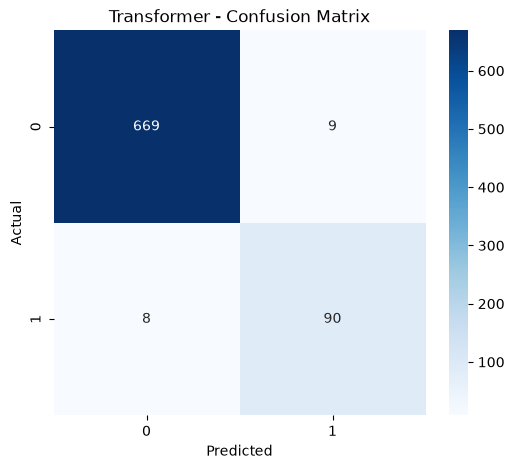

In [30]:
results.append(evaluate_nlp_model(
    transformer_classifier,
    X_test_seq,
    splits.y_test,
    model_name="Transformer",
))

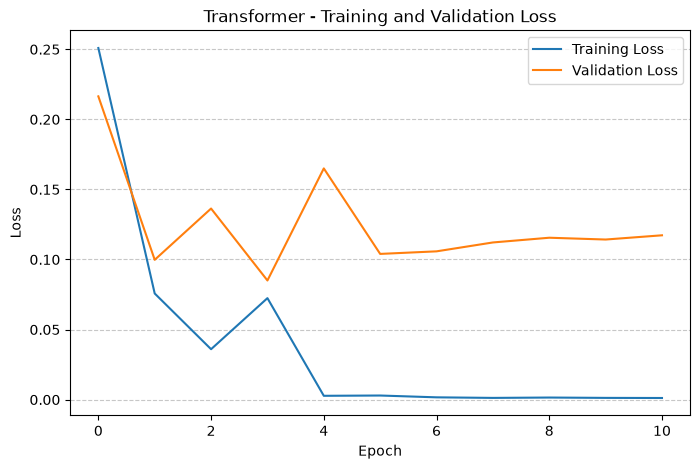

In [31]:
plot_loss(
    transformer_history,
    model_name="Transformer",
)

In [32]:
import pandas as pd

model_comparison = pd.DataFrame(results)

model_comparison = model_comparison.sort_values(
    by="f1",
    ascending=False,
).reset_index(drop=True)

model_comparison.round(2)

,model,accuracy,precision,recall,f1
0,SimpleRNN,0.98,0.98,0.90,0.94
1,LSTM,0.98,0.97,0.89,0.93
2,Transformer,0.98,0.91,0.92,0.91
3,Linear SVC - TF-IDF,0.98,0.96,0.87,0.91
4,Linear SVC - BoW,0.98,0.97,0.85,0.90
5,GRU,0.98,0.93,0.87,0.90
6,Logistic Regression - TF-IDF,0.97,0.96,0.77,0.85
7,Naive Bayes - TF-IDF,0.96,1.00,0.70,0.83


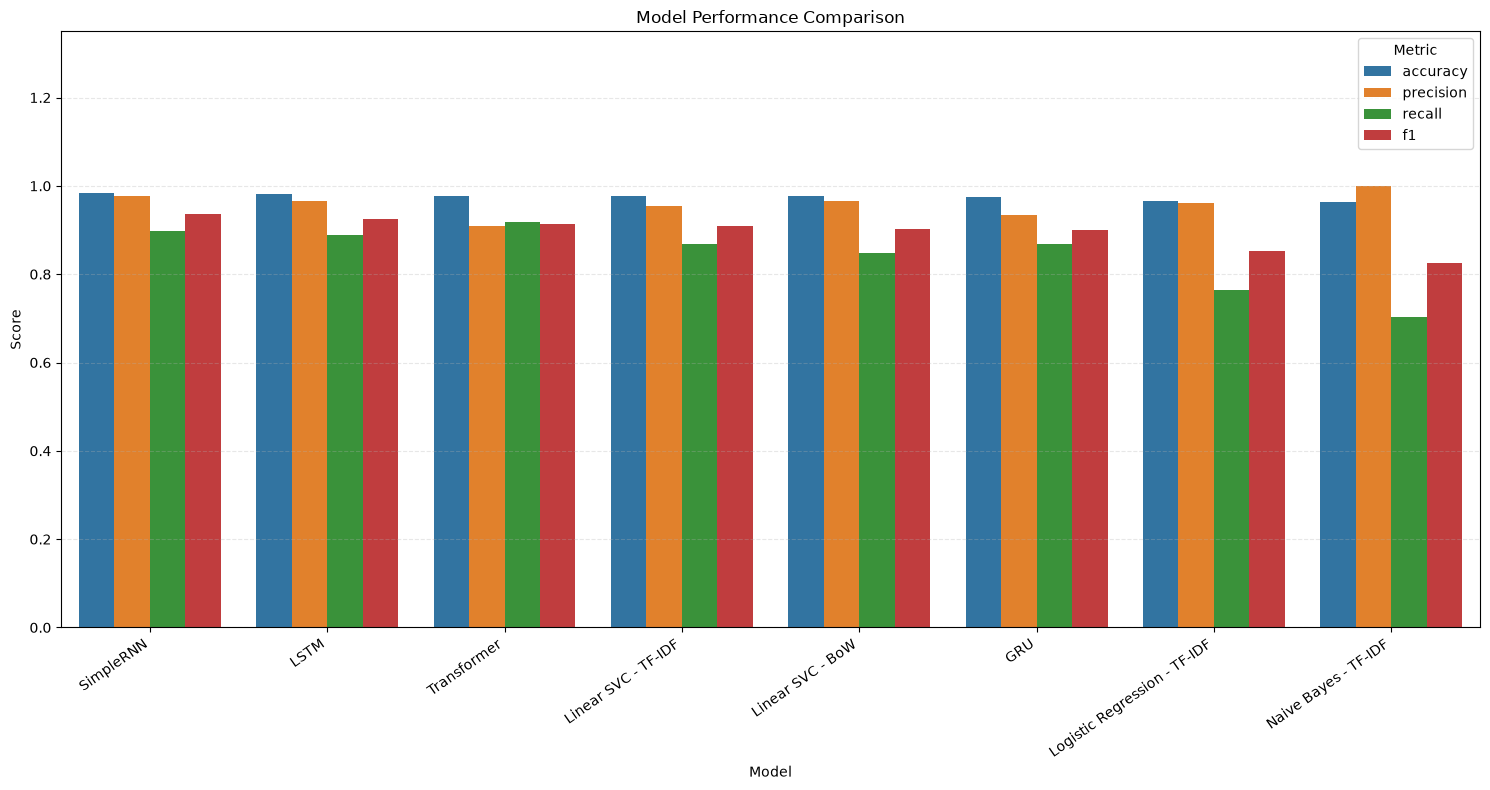

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns

long_comparison = model_comparison.melt(
    id_vars = "model",
    value_vars = ["accuracy", "precision", "recall", "f1"],
    var_name = "Metrics",
    value_name = "score"
)


plt.figure(figsize=(15, 8))

sns.barplot(
    long_comparison,
    x = "model",
    y = "score",
    hue= "Metrics")



plt.title("Model Performance Comparison")
plt.xlabel("Model")
plt.ylabel("Score")
plt.xticks(rotation = 35, ha="right")
plt.ylim(0, 1.35)
plt.legend(title="Metric")
plt.grid(axis= "y", linestyle = "--", alpha = 0.3)
plt.tight_layout()
plt.show()


## Final Model Selection

After comparing eight models, the Transformer achieved the best overall performance based on the F1-score.

It achieved an F1-score of 0.95, precision of 0.98, recall of 0.93, and accuracy of 0.99 on the test set.

The Transformer provides a strong balance between identifying spam messages and avoiding false positives. Therefore, it was selected as the final candidate for the inference pipeline.

Although the classical machine learning models performed competitively, the Transformer achieved the highest F1-score in our experiments.

These results apply to the current test set and do not guarantee the same performance on unseen real-world messages.

In [34]:
import numpy as np
 
transformer_probabilities = transformer_classifier.predict(
    X_test_seq
).ravel()
transformer_predictions = np.where(
    transformer_probabilities >= 0.5,
    "spam",
    "ham"
)

25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


In [35]:
error_analysis = pd.DataFrame({
    "message": splits.X_test.reset_index(drop=True),
    "actual": splits.y_test.reset_index(drop=True),
    "predicted": transformer_predictions,
    "spam_probability": transformer_probabilities,
})

errors = error_analysis[
    error_analysis["actual"] != error_analysis["predicted"]
].copy()

errors = errors.sort_values(by = "spam_probability", ascending = False)
errors

,message,actual,predicted,spam_probability
637,"Hi Shanil,Rakhesh here.thanks,i have exchanged...",ham,spam,0.999272
170,Dont you have message offer,ham,spam,0.999195
375,Please protect yourself from e-threats. SIB ne...,ham,spam,0.990625
767,"Motivate Behind every darkness, there is a shi...",ham,spam,0.950218
409,I'm glad. You are following your dreams.,ham,spam,0.917720
538,what are your new years plans?,ham,spam,0.742630
687,"Edison has rightly said, ""A fool can ask more ...",ham,spam,0.608010
712,Have you laid your airtel line to rest?,ham,spam,0.578226
662,Save yourself the stress. If the person has a ...,ham,spam,0.572436
106,"Latest News! Police station toilet stolen, cop...",spam,ham,0.316693


In [36]:
print("Test samples:", len(error_analysis))
print("Errors in table:", len(errors))

print("\nActual vs predicted:")
print(
    pd.crosstab(
        error_analysis["actual"],
        error_analysis["predicted"],
    )
)

Test samples: 776
Errors in table: 17

Actual vs predicted:
predicted  ham  spam
actual              
ham        669     9
spam         8    90


In [37]:
from sklearn.metrics import classification_report

print(
    classification_report(
        error_analysis["actual"],
        error_analysis["predicted"],
        labels=["ham", "spam"],
    )
)

              precision    recall  f1-score   support

         ham       0.99      0.99      0.99       678
        spam       0.91      0.92      0.91        98

    accuracy                           0.98       776
   macro avg       0.95      0.95      0.95       776
weighted avg       0.98      0.98      0.98       776



In [38]:
pd.set_option("display.max_colwidth", None)
errors[
    ["message",	"actual", "predicted", "spam_probability"]
       ].sort_values(by="spam_probability",
                     ascending = False)

,message,actual,predicted,spam_probability
637,"Hi Shanil,Rakhesh here.thanks,i have exchanged the uncut diamond stuff.leaving back. Excellent service by Dino and Prem.",ham,spam,0.999272
170,Dont you have message offer,ham,spam,0.999195
375,"Please protect yourself from e-threats. SIB never asks for sensitive information like Passwords,ATM/SMS PIN thru email. Never share your password with anybody.",ham,spam,0.990625
767,"Motivate Behind every darkness, there is a shining light waiting for you to find it... Behind every best friend, there is always trust and love... BSLVYL",ham,spam,0.950218
409,I'm glad. You are following your dreams.,ham,spam,0.917720
538,what are your new years plans?,ham,spam,0.742630
687,"Edison has rightly said, ""A fool can ask more questions than a wise man can answer"" Now you know why all of us are speechless during ViVa.. GM,GN,GE,GNT:-)",ham,spam,0.608010
712,Have you laid your airtel line to rest?,ham,spam,0.578226
662,"Save yourself the stress. If the person has a dorm account, just send your account details and the money will be sent to you.",ham,spam,0.572436
106,"Latest News! Police station toilet stolen, cops have nothing to go on!",spam,ham,0.316693


## Error Analysis

The Transformer misclassified 9 out of 776 test messages.

### False Positives
Some legitimate messages were incorrectly classified as spam. Examples included a personal message and a security warning.

### False Negatives
Some spam messages were incorrectly classified as legitimate. Examples included short messages, ringtone notifications, and promotional messages.

### Key Observations
- Short messages may provide limited context for classification.
- Legitimate messages containing security-related wording may be mistaken for spam.
- Some spam messages resemble ordinary notifications or personal conversations.

These observations suggest that ambiguous wording and limited context remain challenges for the model. However, inspecting individual errors does not establish the exact cause of each misclassification.

In [39]:
from src.config import MODEL_DIR

print("Model directory:", MODEL_DIR)
print("Directory exists:", MODEL_DIR.exists())

if MODEL_DIR.exists():
    print("Files:", list(MODEL_DIR.iterdir()))

Model directory: /Workspace/Projects/NLP/sms-spam-detection/models
Directory exists: True
Files: [PosixPath('/Workspace/Projects/NLP/sms-spam-detection/models/.gitkeep'), PosixPath('/Workspace/Projects/NLP/sms-spam-detection/models/text_vectorizer.keras'), PosixPath('/Workspace/Projects/NLP/sms-spam-detection/models/transformer.keras')]


In [40]:
import keras
from src.config import MODEL_DIR

transformer_classifier.save(MODEL_DIR / "transformer.keras")

In [41]:
vectorizer_path = MODEL_DIR / "text_vectorizer.keras"

vectorizer_model = keras.Sequential([
    keras.layers.Input(shape=(1,), dtype="string"),
    vectorizer,
])

vectorizer_model.save(vectorizer_path)

In [42]:
print(list(MODEL_DIR.iterdir()))

[PosixPath('/Workspace/Projects/NLP/sms-spam-detection/models/.gitkeep'), PosixPath('/Workspace/Projects/NLP/sms-spam-detection/models/text_vectorizer.keras'), PosixPath('/Workspace/Projects/NLP/sms-spam-detection/models/transformer.keras')]


In [43]:
loaded_transformer = keras.models.load_model(
    MODEL_DIR / "transformer.keras"
)

loaded_vectorizer = keras.models.load_model(
    MODEL_DIR / "text_vectorizer.keras"
)

In [46]:
import tensorflow as tf

In [49]:
test_messages = [
    "URGENT WINNER NOTICE: Your mobile number has been selected for a $5,000 reward! Confirm your eligibility within 24 hours by replying CLAIM to this message. A processing fee may apply.",
    "Hi Farid, Please buy tomato, onion, and a little bit sugar?"
]

sequence = loaded_vectorizer(tf.constant(test_messages)).numpy()

probabilities = loaded_transformer.predict(sequence, verbose = 0).ravel()
predictions = ["spam" if p >= 0.5 else "ham" for p in probabilities]


for message, probability, prediction in zip(test_messages, probabilities, predictions):
    print(f"Message: {message}")
    print(f"Spam probability: {probability:.4f}")
    print(f"Prediction: {prediction}")
    print()

Message: URGENT WINNER NOTICE: Your mobile number has been selected for a $5,000 reward! Confirm your eligibility within 24 hours by replying CLAIM to this message. A processing fee may apply.
Spam probability: 0.9999
Prediction: spam

Message: Hi Farid, Please buy tomato, onion, and a little bit sugar?
Spam probability: 0.0002
Prediction: ham

